In [1]:
# Imports and Configurations

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 140)

# Folder containing LBNL CSV files
DATA_DIR = Path(r"C:\Users\tjoldham\Documents\Classes\MADS\Programming\DSCI8413\LBNL_FDD_Data_Sets\Chiller_Plant\LBNL_FDD_Dataset_Chiller_Plant")

csv_files = sorted(DATA_DIR.glob("*.csv"))

print(f"CSV files found: {len(csv_files)}")

for f in csv_files:
    print(f.name)

CSV files found: 24
ChillerPlant.csv
ChillerPlant_bypass_leakage_025.csv
ChillerPlant_bypass_leakage_050.csv
ChillerPlant_bypass_leakage_075.csv
ChillerPlant_bypass_stuck_050.csv
ChillerPlant_bypass_stuck_075.csv
ChillerPlant_chiller_bias_-1.csv
ChillerPlant_chiller_bias_-2.csv
ChillerPlant_chiller_bias_1.csv
ChillerPlant_chiller_bias_2.csv
ChillerPlant_chiller_fouling_065.csv
ChillerPlant_chiller_fouling_095.csv
ChillerPlant_coolingtower_bias_-1.csv
ChillerPlant_coolingtower_bias_-2.csv
ChillerPlant_coolingtower_bias_1.csv
ChillerPlant_coolingtower_bias_2.csv
ChillerPlant_coolingtower_fouling_065.csv
ChillerPlant_coolingtower_fouling_080.csv
ChillerPlant_coolingtower_fouling_095.csv
ChillerPlant_coolingtower_PI.csv
ChillerPlant_secondary_chilled_water_pressure_bias_-010.csv
ChillerPlant_secondary_chilled_water_pressure_bias_-020.csv
ChillerPlant_secondary_chilled_water_pressure_bias_010.csv
ChillerPlant_secondary_chilled_water_pressure_bias_020.csv


In [2]:
# ---------------------------------------------------------------
# Parse fault label + intensity from filename, load one file to
# inspect real column names/dtypes before batch-loading everything
# ---------------------------------------------------------------
import re

def parse_fault_label(filename: str) -> dict:
    """Extract fault_type and fault_intensity from LBNL chiller plant filenames."""
    stem = filename.replace(".csv", "")
    if stem == "ChillerPlant":
        return {"fault_type": "fault_free", "fault_intensity": None}
    # e.g. ChillerPlant_chiller_bias_-2, ChillerPlant_bypass_leakage_025,
    #      ChillerPlant_coolingtower_PI, ChillerPlant_secondary_chilled_water_pressure_bias_-020
    m = re.match(r"ChillerPlant_(.+)_(-?\d+)$", stem)
    if m:
        return {"fault_type": m.group(1), "fault_intensity": m.group(2)}
    # handles ChillerPlant_coolingtower_PI (no trailing numeric intensity)
    return {"fault_type": stem.replace("ChillerPlant_", ""), "fault_intensity": "faulted"}

label_map = {f.name: parse_fault_label(f.name) for f in csv_files}
pd.DataFrame(label_map).T

,fault_type,fault_intensity
ChillerPlant.csv,fault_free,NaN
ChillerPlant_bypass_leakage_025.csv,bypass_leakage,025
ChillerPlant_bypass_leakage_050.csv,bypass_leakage,050
ChillerPlant_bypass_leakage_075.csv,bypass_leakage,075
ChillerPlant_bypass_stuck_050.csv,bypass_stuck,050
ChillerPlant_bypass_stuck_075.csv,bypass_stuck,075
ChillerPlant_chiller_bias_-1.csv,chiller_bias,-1
ChillerPlant_chiller_bias_-2.csv,chiller_bias,-2
ChillerPlant_chiller_bias_1.csv,chiller_bias,1
ChillerPlant_chiller_bias_2.csv,chiller_bias,2


In [3]:
# ---------------------------------------------------------------
# Inspect ONE file first — confirm timestamp column, dtypes, shape
# ---------------------------------------------------------------
sample = pd.read_csv(csv_files[0])
print(sample.shape)
print(sample.columns.tolist())
sample.head()

(525540, 78)
['Datetime', 'CDWL_CW_FLOW', 'CDWL_PM_POW_1', 'CDWL_PM_POW_2', 'CDWL_PM_POW_3', 'CDWL_RW_TEMP', 'CDWL_SW_TEMP', 'CHL_CD_FLOW_1', 'CHL_CD_FLOW_2', 'CHL_CD_FLOW_3', 'CHL_COMP_SPD_CTRL_1', 'CHL_COMP_SPD_CTRL_2', 'CHL_COMP_SPD_CTRL_3', 'CHL_CW_FLOW_1', 'CHL_CW_FLOW_2', 'CHL_CW_FLOW_3', 'CHL_POW_1', 'CHL_POW_2', 'CHL_POW_3', 'CHL_SWCD_TEMP_1', 'CHL_SWCD_TEMP_2', 'CHL_SWCD_TEMP_3', 'CHL_RW_TEMP_1', 'CHL_RW_TEMP_2', 'CHL_RW_TEMP_3', 'CHL_STA_1', 'CHL_STA_2', 'CHL_STA_3', 'CHL_RWCD_TEMP_1', 'CHL_RWCD_TEMP_2', 'CHL_RWCD_TEMP_3', 'CHL_SW_TEMP_1', 'CHL_SW_TEMP_2', 'CHL_SW_TEMP_3', 'CT_FAN_SPD_1', 'CT_FAN_SPD_2', 'CT_FAN_SPD_3', 'CT_FAN_SPD_CTRL_1', 'CT_FAN_SPD_CTRL_2', 'CT_FAN_SPD_CTRL_3', 'CT_FLOW_1', 'CT_FLOW_2', 'CT_FLOW_3', 'CT_POW_1', 'CT_POW_2', 'CT_POW_3', 'CT_RW_TEMP_1', 'CT_RW_TEMP_2', 'CT_RW_TEMP_3', 'CT_STA_1', 'CT_STA_2', 'CT_STA_3', 'CT_SW_TEMPSPT', 'CT_SW_TEMP_1', 'CT_SW_TEMP_2', 'CT_SW_TEMP_3', 'CWL_PRI_CW_FLOW', 'CWL_PRI_PM_POW_1', 'CWL_PRI_PM_POW_2', 'CWL_PRI_PM_POW_

,Datetime,CDWL_CW_FLOW,CDWL_PM_POW_1,CDWL_PM_POW_2,CDWL_PM_POW_3,CDWL_RW_TEMP,CDWL_SW_TEMP,CHL_CD_FLOW_1,CHL_CD_FLOW_2,CHL_CD_FLOW_3,CHL_COMP_SPD_CTRL_1,CHL_COMP_SPD_CTRL_2,CHL_COMP_SPD_CTRL_3,CHL_CW_FLOW_1,CHL_CW_FLOW_2,CHL_CW_FLOW_3,CHL_POW_1,CHL_POW_2,CHL_POW_3,CHL_SWCD_TEMP_1,CHL_SWCD_TEMP_2,CHL_SWCD_TEMP_3,CHL_RW_TEMP_1,CHL_RW_TEMP_2,CHL_RW_TEMP_3,CHL_STA_1,CHL_STA_2,CHL_STA_3,CHL_RWCD_TEMP_1,CHL_RWCD_TEMP_2,CHL_RWCD_TEMP_3,CHL_SW_TEMP_1,CHL_SW_TEMP_2,CHL_SW_TEMP_3,CT_FAN_SPD_1,CT_FAN_SPD_2,CT_FAN_SPD_3,CT_FAN_SPD_CTRL_1,CT_FAN_SPD_CTRL_2,CT_FAN_SPD_CTRL_3,CT_FLOW_1,CT_FLOW_2,CT_FLOW_3,CT_POW_1,CT_POW_2,CT_POW_3,CT_RW_TEMP_1,CT_RW_TEMP_2,CT_RW_TEMP_3,CT_STA_1,CT_STA_2,CT_STA_3,CT_SW_TEMPSPT,CT_SW_TEMP_1,CT_SW_TEMP_2,CT_SW_TEMP_3,CWL_PRI_CW_FLOW,CWL_PRI_PM_POW_1,CWL_PRI_PM_POW_2,CWL_PRI_PM_POW_3,CWL_PRI_RW_TEMP,CWL_PRI_SW_TEMP,CWL_PRI_SW_TEMPSPT,CWL_SEC_CW_FLOW,CWL_SEC_DP,CWL_SEC_DPSPT,CWL_SEC_LOAD,CWL_SEC_PM_POW_1,CWL_SEC_PM_POW_2,CWL_SEC_PM_SPD_1,CWL_SEC_PM_SPD_2,CWL_SEC_PM_STA_1,CWL_SEC_PM_STA_2,CWL_SEC_RW_TEMP,CWL_SEC_SW_TEMP,OA_TEMP,OA_TEMP_WB,TWV_CTRL
0,2018-01-01 01:00:00,321.582963,46.084146,0.000000e+00,0.000000e+00,69.188995,61.984875,321.582107,0.000429,0.000429,0.497262,0.0,0.0,279.324281,0.000372,0.000372,69.507398,0.0,0.0,69.17861,74.99603,74.99603,57.255424,42.227337,42.227337,1.0,0.0,0.0,62.262770,75.559970,75.559970,51.432564,42.049248,42.049248,0.341687,0.0,0.0,0.341687,0.0,0.0,318.419286,0.000222,0.000222,0.499460,0.0,0.0,69.178665,68.70455,68.70455,1.0,0.0,0.0,60.007996,61.911266,69.697495,69.697495,279.325015,15.021188,0.000000e+00,0.000000e+00,57.262290,51.431625,53.999626,461.473576,529.201971,960.960802,22551.240,53.638358,0.000000,1.000000,0.000000,1.0,0.0,56.816963,57.150177,9.070051,10.355011,0.0
1,2018-01-01 01:01:00,321.582963,46.084146,0.000000e+00,0.000000e+00,68.880936,61.921814,321.582107,0.000429,0.000429,0.477222,0.0,0.0,279.324281,0.000372,0.000372,66.280762,0.0,0.0,68.87072,74.99603,74.99603,57.055916,42.227337,42.227337,1.0,0.0,0.0,62.199715,75.559906,75.559906,51.460247,42.049248,42.049248,0.333905,0.0,0.0,0.333905,0.0,0.0,318.419286,0.000222,0.000222,0.460999,0.0,0.0,68.870770,68.70455,68.70455,1.0,0.0,0.0,60.007996,61.850730,69.697495,69.697495,279.325015,15.021188,3.107657e-21,1.041529e-21,57.062508,51.459260,53.999626,461.473576,529.201971,960.960802,21665.527,53.638358,0.000000,1.000000,0.000000,1.0,0.0,56.630524,56.950665,8.771828,10.040033,0.0
2,2018-01-01 01:02:00,321.582963,46.084146,3.512600e-18,1.600030e-34,68.577880,61.861610,321.582107,0.000429,0.000429,0.457744,0.0,0.0,279.324281,0.000372,0.000372,63.233582,0.0,0.0,68.56789,74.99603,74.99603,56.863213,42.227394,42.227394,1.0,0.0,0.0,62.139565,75.559906,75.559906,51.488262,42.049248,42.049248,0.327008,0.0,0.0,0.327008,0.0,0.0,318.419286,0.000222,0.000222,0.425439,0.0,0.0,68.567930,68.70455,68.70455,1.0,0.0,0.0,60.007996,61.793000,69.697495,69.697495,279.325015,15.021188,0.000000e+00,0.000000e+00,56.869530,51.487328,53.999626,461.473576,529.201971,960.960802,20804.450,53.638358,0.000000,1.000000,0.000000,1.0,0.0,56.450570,56.757965,8.786055,10.055031,0.0
3,2018-01-01 01:03:00,321.582963,46.084146,0.000000e+00,0.000000e+00,68.299484,61.804260,321.582107,0.000429,0.000429,0.482627,0.0,0.0,279.324281,0.000372,0.000372,66.893384,0.0,0.0,68.29224,74.99603,74.99603,58.332360,42.227394,42.227394,1.0,0.0,0.0,62.082268,75.559906,75.559906,51.595047,42.049248,42.049248,0.320856,0.0,0.0,0.320856,0.0,0.0,318.419286,0.000222,0.000222,0.392423,0.0,0.0,68.292290,68.70455,68.70455,1.0,0.0,0.0,60.007996,61.737957,69.697495,69.697495,279.325015,15.021188,0.000000e+00,0.000000e+00,58.238647,51.587250,53.999626,754.161433,864.846296,960.960802,0.000,52.330258,44.184977,1.000000,1.000000,1.0,1.0,61.190950,58.270123,8.800337,10.070026,0.0
4,2018-01-01 01:04:00,321.582963,46.084146,0.000000e+00,0.000000e+00,68.241200,61.761360,321.582107,0.000429,0.000429,0.626781,0.0,0.0,279.324281,0.000372,0.000372,91.014646,0.0,0.0,68.24450,74.99603,74.99603,

In [4]:
# ---------------------------------------------------------------
# Load all files into one long DataFrame, tagging each row with
# its source file / fault label so scenarios stay identifiable
# ---------------------------------------------------------------
TIMESTAMP_COL = sample.columns[0]  # confirm this after viewing sample.head() above

dfs = []
for f in csv_files:
    df = pd.read_csv(f)
    df["source_file"] = f.name
    df["fault_type"] = label_map[f.name]["fault_type"]
    df["fault_intensity"] = label_map[f.name]["fault_intensity"]
    dfs.append(df)

data = pd.concat(dfs, ignore_index=True)
print(f"Combined shape: {data.shape}")
del dfs  # free memory once concatenated

Combined shape: (12612960, 81)


In [5]:
# ---------------------------------------------------------------
# Save combined raw dataset as an intermediate file, so downstream
# notebooks (cleaning/transformation, modeling) don't need to
# re-parse and re-concatenate all 24 CSVs from scratch
# ---------------------------------------------------------------
data.to_parquet("raw_combined.parquet", index=False)
print(f"Saved intermediate file: {data.shape} -> raw_combined.parquet")

Saved intermediate file: (12612960, 81) -> raw_combined.parquet


In [6]:
# ---------------------------------------------------------------
# Observations & Variables — per file and combined
# ---------------------------------------------------------------
shape_summary = pd.DataFrame({
    "n_rows": {f.name: pd.read_csv(f, usecols=[0]).shape[0] for f in csv_files}
})
shape_summary["fault_type"] = shape_summary.index.map(lambda n: label_map[n]["fault_type"])
print(shape_summary)
print(f"\nTotal combined rows: {data.shape[0]:,}")
print(f"Total combined columns (incl. label cols): {data.shape[1]}")

                                                    n_rows                             fault_type
ChillerPlant.csv                                    525540                             fault_free
ChillerPlant_bypass_leakage_025.csv                 525540                         bypass_leakage
ChillerPlant_bypass_leakage_050.csv                 525540                         bypass_leakage
ChillerPlant_bypass_leakage_075.csv                 525540                         bypass_leakage
ChillerPlant_bypass_stuck_050.csv                   525540                           bypass_stuck
ChillerPlant_bypass_stuck_075.csv                   525540                           bypass_stuck
ChillerPlant_chiller_bias_-1.csv                    525540                           chiller_bias
ChillerPlant_chiller_bias_-2.csv                    525540                           chiller_bias
ChillerPlant_chiller_bias_1.csv                     525540                           chiller_bias
ChillerPlant_chiller

In [7]:
# ---------------------------------------------------------------
# Variable / data types
# ---------------------------------------------------------------
dtype_summary = data.dtypes.value_counts()
print(dtype_summary)

data.dtypes.astype(str).sort_values().to_frame("dtype")

float64    77
str         3
object      1
Name: count, dtype: int64


,dtype
CDWL_CW_FLOW,float64
CDWL_PM_POW_1,float64
CDWL_PM_POW_2,float64
CDWL_PM_POW_3,float64
CDWL_RW_TEMP,float64
CDWL_SW_TEMP,float64
CHL_CD_FLOW_1,float64
CHL_CD_FLOW_2,float64
CHL_CD_FLOW_3,float64
CHL_COMP_SPD_CTRL_1,float64


In [8]:
# ---------------------------------------------------------------
# Missing values — count and % per column, worst offenders first
# ---------------------------------------------------------------
missing = data.isna().sum()
missing_pct = (missing / len(data) * 100).round(3)
missing_report = pd.DataFrame({"n_missing": missing, "pct_missing": missing_pct})
missing_report = missing_report[missing_report["n_missing"] > 0].sort_values("pct_missing", ascending=False)
missing_report

,n_missing,pct_missing
fault_intensity,525540,4.167


In [9]:
# ---------------------------------------------------------------
# Duplicate records — full-row dupes, and dupes within a single
# scenario on the timestamp (would indicate a real logging problem)
# ---------------------------------------------------------------
full_dupes = data.duplicated().sum()
print(f"Full-row duplicates: {full_dupes}")

ts_dupes = (
    data.groupby("source_file")[TIMESTAMP_COL]
    .apply(lambda s: s.duplicated().sum())
)
print("\nDuplicate timestamps within each file:")
print(ts_dupes[ts_dupes > 0])

Full-row duplicates: 0

Duplicate timestamps within each file:
Series([], Name: Datetime, dtype: int64)


In [10]:
# ---------------------------------------------------------------
# Date/time inconsistencies — monotonic order, gaps, row-count
# mismatch vs. expected 1-minute-frequency full year
# ---------------------------------------------------------------
data[TIMESTAMP_COL] = pd.to_datetime(data[TIMESTAMP_COL], errors="coerce")
print(f"Unparseable timestamps: {data[TIMESTAMP_COL].isna().sum()}")

for name, grp in data.groupby("source_file"):
    ts = grp[TIMESTAMP_COL].sort_values()
    is_monotonic = ts.is_monotonic_increasing
    gaps = ts.diff().value_counts().head(3)
    print(f"{name}: monotonic={is_monotonic}, span={ts.min()} to {ts.max()}")

Unparseable timestamps: 0
ChillerPlant.csv: monotonic=True, span=2018-01-01 01:00:00 to 2018-12-31 23:59:00
ChillerPlant_bypass_leakage_025.csv: monotonic=True, span=2018-01-01 01:00:00 to 2018-12-31 23:59:00
ChillerPlant_bypass_leakage_050.csv: monotonic=True, span=2018-01-01 01:00:00 to 2018-12-31 23:59:00
ChillerPlant_bypass_leakage_075.csv: monotonic=True, span=2018-01-01 01:00:00 to 2018-12-31 23:59:00
ChillerPlant_bypass_stuck_050.csv: monotonic=True, span=2018-01-01 01:00:00 to 2018-12-31 23:59:00
ChillerPlant_bypass_stuck_075.csv: monotonic=True, span=2018-01-01 01:00:00 to 2018-12-31 23:59:00
ChillerPlant_chiller_bias_-1.csv: monotonic=True, span=2018-01-01 01:00:00 to 2018-12-31 23:59:00
ChillerPlant_chiller_bias_-2.csv: monotonic=True, span=2018-01-01 01:00:00 to 2018-12-31 23:59:00
ChillerPlant_chiller_bias_1.csv: monotonic=True, span=2018-01-01 01:00:00 to 2018-12-31 23:59:00
ChillerPlant_chiller_bias_2.csv: monotonic=True, span=2018-01-01 01:00:00 to 2018-12-31 23:59:00
C

In [11]:
# ---------------------------------------------------------------
# Outliers & Invalid/impossible values
# Split: distributional outliers (IQR) vs. physically impossible
# values (status flags outside {0,1}, control signals outside 0-1)
# ---------------------------------------------------------------
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in ("fault_intensity",)]

# IQR-based outlier flag count per numeric column
outlier_counts = {}
for col in numeric_cols:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_counts[col] = ((data[col] < lower) | (data[col] > upper)).sum()

outlier_report = pd.Series(outlier_counts).sort_values(ascending=False)
print(outlier_report.head(20))
print(f"\nColumns with >1% of rows flagged as IQR outliers:")
print((outlier_report / len(data) * 100).round(2)[lambda s: s > 1])

# Physically impossible values for known 0-1 / 0-Off,1-On columns
status_cols = [c for c in data.columns if c.endswith(("_STA", "_STA_1", "_STA_2", "_STA_3"))]
zero_one_cols = [c for c in data.columns if "SPD" in c or "CTRL" in c]

for col in status_cols:
    bad = data[col][~data[col].isin([0, 1])]
    if len(bad):
        print(f"\n{col}: {len(bad)} values outside {{0,1}} — range {bad.min()} to {bad.max()}")

for col in zero_one_cols:
    bad = data[col][(data[col] < 0) | (data[col] > 1)]
    if len(bad):
        print(f"\n{col}: {len(bad)} values outside [0,1] — range {bad.min()} to {bad.max()}")

CHL_RW_TEMP_1          5292314
CWL_PRI_RW_TEMP        5292027
CHL_CD_FLOW_1          4031938
CHL_CW_FLOW_1          4031719
CWL_SEC_SW_TEMP        3810955
CWL_SEC_RW_TEMP        3433190
CWL_SEC_LOAD           3385637
CHL_SW_TEMP_1          3029266
CDWL_PM_POW_2          2999669
CDWL_PM_POW_3          2933414
CWL_PRI_PM_POW_2       2784890
CT_POW_1               2749248
CWL_PRI_PM_POW_3       2649682
CWL_PRI_SW_TEMP        2239965
CHL_SWCD_TEMP_2        2120813
CHL_POW_1              2113995
CT_SW_TEMP_2           1760037
CHL_COMP_SPD_CTRL_1    1719501
CT_FAN_SPD_CTRL_1      1553506
CT_FAN_SPD_1           1553506
dtype: int64

Columns with >1% of rows flagged as IQR outliers:
CHL_RW_TEMP_1          41.96
CWL_PRI_RW_TEMP        41.96
CHL_CD_FLOW_1          31.97
CHL_CW_FLOW_1          31.96
CWL_SEC_SW_TEMP        30.21
CWL_SEC_RW_TEMP        27.22
CWL_SEC_LOAD           26.84
CHL_SW_TEMP_1          24.02
CDWL_PM_POW_2          23.78
CDWL_PM_POW_3          23.26
CWL_PRI_PM_POW_2       22.

In [12]:
# ---------------------------------------------------------------
# Categorical-variable issues — confirm status/flag columns
# only take their expected discrete values
# ---------------------------------------------------------------
for col in status_cols:
    print(f"{col}: {sorted(data[col].dropna().unique())}")

CHL_STA_1: [np.float64(1.0)]
CHL_STA_2: [np.float64(0.0), np.float64(1.0)]
CHL_STA_3: [np.float64(0.0), np.float64(1.0)]
CT_STA_1: [np.float64(1.0)]
CT_STA_2: [np.float64(0.0), np.float64(1.0)]
CT_STA_3: [np.float64(0.0), np.float64(1.0)]
CWL_SEC_PM_STA_1: [np.float64(1.0)]
CWL_SEC_PM_STA_2: [np.float64(0.0), np.float64(1.0)]


In [13]:
# ---------------------------------------------------------------
# Class imbalance — row counts and scenario counts by fault_type
# ---------------------------------------------------------------
print("Row-level counts by fault_type:")
print(data["fault_type"].value_counts())

print("\nAs % of total rows:")
print((data["fault_type"].value_counts(normalize=True) * 100).round(2))

# Fault-free vs faulted at the file/scenario level (avoids the row-level
# imbalance masking how balanced the *scenario* design actually is)
scenario_counts = pd.Series({n: v["fault_type"] for n, v in label_map.items()}).value_counts()
print("\nScenario (file) counts by fault_type:")
print(scenario_counts)

Row-level counts by fault_type:
fault_type
chiller_bias                             2102160
coolingtower_bias                        2102160
secondary_chilled_water_pressure_bias    2102160
bypass_leakage                           1576620
coolingtower_fouling                     1576620
bypass_stuck                             1051080
chiller_fouling                          1051080
fault_free                                525540
coolingtower_PI                           525540
Name: count, dtype: int64

As % of total rows:
fault_type
chiller_bias                             16.67
coolingtower_bias                        16.67
secondary_chilled_water_pressure_bias    16.67
bypass_leakage                           12.50
coolingtower_fouling                     12.50
bypass_stuck                              8.33
chiller_fouling                           8.33
fault_free                                4.17
coolingtower_PI                           4.17
Name: proportion, dtype: float64

S

In [14]:
# ---------------------------------------------------------------
# Scale differences among numeric variables — group by unit
# family so the magnitude mismatch is obvious before any scaling
# ---------------------------------------------------------------
unit_groups = {
    "temperature_F": [c for c in numeric_cols if "TEMP" in c and "SPD" not in c],
    "flow_GPM": [c for c in numeric_cols if "FLOW" in c],
    "power_kW": [c for c in numeric_cols if "POW" in c],
    "pressure_inH2O": [c for c in numeric_cols if "_DP" in c],
    "normalized_0_1": [c for c in numeric_cols if "SPD" in c or "CTRL" in c],
}

for group_name, cols in unit_groups.items():
    if cols:
        desc = data[cols].describe().T[["min", "mean", "max", "std"]]
        print(f"\n--- {group_name} ---")
        print(desc)


--- temperature_F ---
                          min       mean         max        std
CDWL_RW_TEMP        41.637154  71.863487  163.376920  20.228844
CDWL_SW_TEMP        41.491310  70.321949  162.350200  19.459286
CHL_SWCD_TEMP_1     41.637043  71.867579  163.377150  20.231061
CHL_SWCD_TEMP_2     67.285510  75.991035  127.408295   7.279534
CHL_SWCD_TEMP_3     73.132866  78.418754   95.671430   4.895523
CHL_RW_TEMP_1       39.088158  55.045666  108.865520   6.114586
CHL_RW_TEMP_2       39.609516  48.649641   79.680600   5.397345
CHL_RW_TEMP_3       40.907550  48.470531   61.277190   5.055465
CHL_RWCD_TEMP_1     41.537617  70.443551  162.396290  19.459974
CHL_RWCD_TEMP_2     64.573580  75.024620  122.809080   7.176063
CHL_RWCD_TEMP_3     73.124300  77.145917   88.006820   3.279067
CHL_SW_TEMP_1       39.753216  53.604575  108.014180   6.405103
CHL_SW_TEMP_2       39.746845  46.400328   71.674866   3.845926
CHL_SW_TEMP_3       42.040240  45.756616   50.357220   2.613377
CT_RW_TEMP_1     

In [15]:
# ---------------------------------------------------------------
# Formatting inconsistencies — confirm every file has identical
# column names/order/count before relying on the concat above
# ---------------------------------------------------------------
col_sets = {f.name: tuple(pd.read_csv(f, nrows=0).columns) for f in csv_files}
reference = col_sets[csv_files[0].name]

mismatches = {name: cols for name, cols in col_sets.items() if cols != reference}
print(f"Files with mismatched columns vs. {csv_files[0].name}: {len(mismatches)}")
for name, cols in mismatches.items():
    print(f"\n{name}:")
    print(f"  Missing: {set(reference) - set(cols)}")
    print(f"  Extra:   {set(cols) - set(reference)}")

Files with mismatched columns vs. ChillerPlant.csv: 0


In [16]:
# ---------------------------------------------------------------
# Data leakage guardrail — flag any column whose values are
# near-perfectly separable by fault_type/source_file, which would
# indicate the model could learn the file identity instead of the
# physical fault signature
# ---------------------------------------------------------------
from sklearn.feature_selection import mutual_info_classif

leak_check_cols = [c for c in numeric_cols if c not in ("fault_intensity",)]
sample_df = data.sample(n=min(200_000, len(data)), random_state=42)  # subsample for speed

mi_scores = mutual_info_classif(
    sample_df[leak_check_cols].fillna(0),
    sample_df["fault_type"],
    discrete_features=False,
    random_state=42,
)
mi_report = pd.Series(mi_scores, index=leak_check_cols).sort_values(ascending=False)
print(mi_report.head(15))

CT_RW_TEMP_2           1.567247
CT_SW_TEMP_3           1.525952
CT_SW_TEMP_2           1.513538
CT_RW_TEMP_3           1.511728
CWL_SEC_RW_TEMP        0.866782
CWL_SEC_SW_TEMP        0.762155
CHL_RWCD_TEMP_2        0.626286
CHL_COMP_SPD_CTRL_1    0.619874
CHL_SWCD_TEMP_2        0.596738
CHL_RW_TEMP_2          0.595024
CHL_CD_FLOW_1          0.582653
CHL_CW_FLOW_1          0.581262
CHL_POW_1              0.560346
CT_FLOW_1              0.495786
CDWL_PM_POW_1          0.495412
dtype: float64


In [17]:
# ---------------------------------------------------------------
# Documentation vs. actual file inventory — flag any scenario
# present in the folder but not described in the LBNL PDF's Table 4
# ---------------------------------------------------------------
documented_fault_types = {
    "fault_free", "chiller_bias", "coolingtower_bias",
    "secondary_chilled_water_pressure_bias", "bypass_leakage",
    "bypass_stuck", "coolingtower_fouling", "coolingtower_PI",
}
actual_fault_types = set(data["fault_type"].unique())

undocumented = actual_fault_types - documented_fault_types
print(f"Fault types present in data but not in the PDF's Table 3/4: {undocumented}")

Fault types present in data but not in the PDF's Table 3/4: {'chiller_fouling'}


In [18]:
# ---------------------------------------------------------------
# Re-run outlier detection WITHIN each fault_type group instead of
# globally, to separate genuine outliers from cross-scenario/
# cross-regime distribution mixing
# ---------------------------------------------------------------
def iqr_outlier_pct(series: pd.Series) -> float:
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).mean() * 100

# Compare global vs. within-group outlier rate for the worst offenders
worst_cols = ["CHL_RW_TEMP_1", "CWL_PRI_RW_TEMP", "CHL_CD_FLOW_1", "CWL_SEC_SW_TEMP"]

within_group = (
    data.groupby("fault_type")[worst_cols]
    .apply(lambda g: g.apply(iqr_outlier_pct))
)
print("Within-group outlier % (should be much lower than the global numbers if this is a mixing artifact):")
print(within_group)

Within-group outlier % (should be much lower than the global numbers if this is a mixing artifact):
                                       CHL_RW_TEMP_1  CWL_PRI_RW_TEMP  CHL_CD_FLOW_1  CWL_SEC_SW_TEMP
fault_type                                                                                           
bypass_leakage                              7.050018         7.050589       1.459451         6.898745
bypass_stuck                                2.426076         2.425886       0.000000         2.418370
chiller_bias                                0.710460         0.710174      12.401340         0.791519
chiller_fouling                            46.301328        46.303231      11.234254        37.436066
coolingtower_PI                            44.455227        44.454466      12.210488        43.082163
coolingtower_bias                          42.909151        42.911244      12.529541        39.388629
coolingtower_fouling                       42.907422        42.908120      12.525085

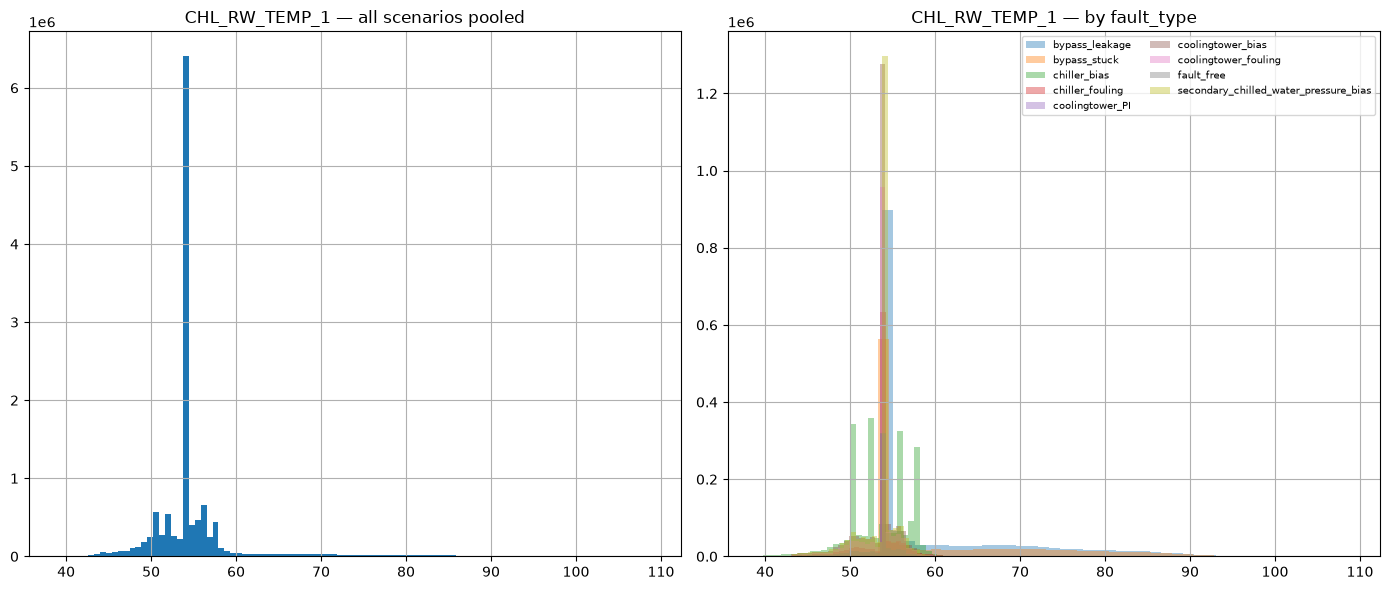

In [19]:
# ---------------------------------------------------------------
# Visual confirmation: is CHL_RW_TEMP_1 multimodal when pooled,
# and does it separate cleanly by fault_type?
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

data["CHL_RW_TEMP_1"].hist(bins=100, ax=axes[0])
axes[0].set_title("CHL_RW_TEMP_1 — all scenarios pooled")

for ft, grp in data.groupby("fault_type"):
    grp["CHL_RW_TEMP_1"].hist(bins=50, alpha=0.4, ax=axes[1], label=ft)
axes[1].set_title("CHL_RW_TEMP_1 — by fault_type")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

In [20]:
# ---------------------------------------------------------------
# Test the staging-regime hypothesis directly: does outlier rate
# collapse once we condition on how many chillers are running?
# ---------------------------------------------------------------
fault_free = data[data["fault_type"] == "fault_free"].copy()
fault_free["n_chillers_on"] = fault_free[["CHL_STA_1", "CHL_STA_2", "CHL_STA_3"]].sum(axis=1)

print(fault_free["n_chillers_on"].value_counts().sort_index())

within_regime = (
    fault_free.groupby("n_chillers_on")["CHL_RW_TEMP_1"]
    .apply(iqr_outlier_pct)
)
print("\nCHL_RW_TEMP_1 outlier % within each staging regime (fault_free only):")
print(within_regime)

n_chillers_on
1.0    460156
2.0     63093
3.0      2291
Name: count, dtype: int64

CHL_RW_TEMP_1 outlier % within each staging regime (fault_free only):
n_chillers_on
1.0    43.036709
2.0     0.955732
3.0     0.000000
Name: CHL_RW_TEMP_1, dtype: float64


In [21]:
# ---------------------------------------------------------------
# Single-chiller operation regime as % of fault-free record
# ---------------------------------------------------------------

regime_counts = fault_free["n_chillers_on"].value_counts().sort_index()
regime_pct = (regime_counts / regime_counts.sum() * 100).round(2)

regime_summary = pd.DataFrame({
    "n_records": regime_counts,
    "pct_of_fault_free": regime_pct
})
print(regime_summary)

single_chiller_pct = regime_pct.loc[1.0]
print(f"\nSingle-chiller operation accounts for {single_chiller_pct}% of fault-free records.")


               n_records  pct_of_fault_free
n_chillers_on                              
1.0               460156              87.56
2.0                63093              12.01
3.0                 2291               0.44

Single-chiller operation accounts for 87.56% of fault-free records.


In [22]:
# ---------------------------------------------------------------
# Same idea, seasonally: does outlier rate collapse when
# conditioned on month (proxy for load/staging regime over the year)?
# ---------------------------------------------------------------
fault_free["month"] = fault_free[TIMESTAMP_COL].dt.month

within_month = fault_free.groupby("month")["CHL_RW_TEMP_1"].apply(iqr_outlier_pct)
print("CHL_RW_TEMP_1 outlier % by month (fault_free only):")
print(within_month)

CHL_RW_TEMP_1 outlier % by month (fault_free only):
month
1      1.994168
2     20.746528
3     17.594086
4     37.895833
5     34.475806
6      2.043981
7      0.591398
8      0.860215
9      0.560185
10    21.025986
11    30.814815
12     0.002240
Name: CHL_RW_TEMP_1, dtype: float64


In [23]:
# ---------------------------------------------------------------
# Confirm the OA-temp reset-band hypothesis directly: outlier rate
# should track time spent with OA_TEMP inside the 60-80°F reset band
# ---------------------------------------------------------------
fault_free["in_reset_band"] = fault_free["OA_TEMP"].between(60, 80)

within_band = fault_free.groupby("in_reset_band")["CHL_RW_TEMP_1"].apply(iqr_outlier_pct)
print("CHL_RW_TEMP_1 outlier % — inside vs. outside the 60-80°F OA reset band:")
print(within_band)

# Cross-check: correlation between OA_TEMP and the setpoint-driven column directly
print("\nCorrelation OA_TEMP vs CWL_PRI_SW_TEMPSPT (the resettable setpoint):")
print(fault_free[["OA_TEMP", "CWL_PRI_SW_TEMPSPT"]].corr().iloc[0, 1])

CHL_RW_TEMP_1 outlier % — inside vs. outside the 60-80°F OA reset band:
in_reset_band
False    42.601691
True      0.300958
Name: CHL_RW_TEMP_1, dtype: float64

Correlation OA_TEMP vs CWL_PRI_SW_TEMPSPT (the resettable setpoint):
-0.7210942891443889


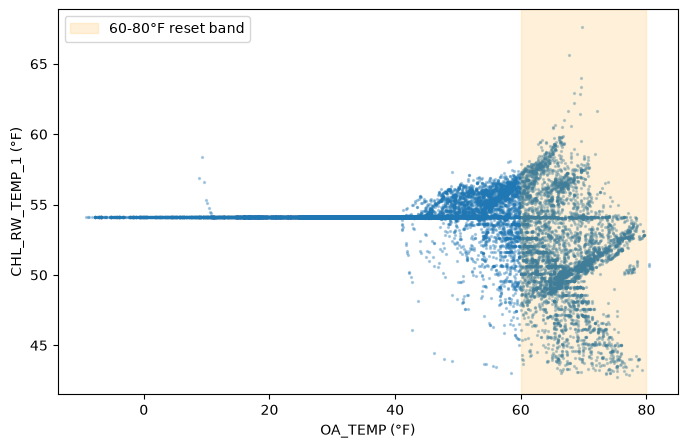

In [24]:
# ---------------------------------------------------------------
# Visual: does CHL_RW_TEMP_1 vs OA_TEMP show the expected reset
# relationship, with the wide spread concentrated in the band?
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
sample_plot = fault_free.sample(n=20_000, random_state=42)
ax.scatter(sample_plot["OA_TEMP"], sample_plot["CHL_RW_TEMP_1"], s=2, alpha=0.3)
ax.axvspan(60, 80, alpha=0.15, color="orange", label="60-80°F reset band")
ax.set_xlabel("OA_TEMP (°F)")
ax.set_ylabel("CHL_RW_TEMP_1 (°F)")
ax.legend()
plt.show()

In [25]:
# ---------------------------------------------------------------
# Near-constant / zero-variance columns — candidates to drop,
# since they can't help distinguish fault vs. normal behavior
# ---------------------------------------------------------------
stds = data[numeric_cols].std()
near_constant = stds[stds < 1e-6].sort_values()
print("Zero/near-zero variance columns:")
print(near_constant)

Zero/near-zero variance columns:
CHL_STA_1           0.0
CT_STA_1            0.0
CWL_SEC_DPSPT       0.0
CWL_SEC_PM_STA_1    0.0
dtype: float64


In [26]:
# ---------------------------------------------------------------
# Split fault_intensity into semantically consistent columns so
# the mixed-unit values (°C offset vs. % vs. "faulted") don't get
# compared on the same numeric scale downstream
# ---------------------------------------------------------------
bias_types = {"chiller_bias", "coolingtower_bias"}
pct_types = {"bypass_leakage", "bypass_stuck", "chiller_fouling",
             "coolingtower_fouling", "secondary_chilled_water_pressure_bias"}

def to_signed_float(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return np.nan

data["intensity_degC"] = np.where(
    data["fault_type"].isin(bias_types),
    data["fault_intensity"].map(to_signed_float),
    np.nan,
)
data["intensity_pct"] = np.where(
    data["fault_type"].isin(pct_types),
    data["fault_intensity"].map(to_signed_float),
    np.nan,
)

print(data[["fault_type", "fault_intensity", "intensity_degC", "intensity_pct"]].drop_duplicates().sort_values("fault_type"))

                                     fault_type fault_intensity  intensity_degC  intensity_pct
525540                           bypass_leakage             025             NaN           25.0
1051080                          bypass_leakage             050             NaN           50.0
1576620                          bypass_leakage             075             NaN           75.0
2102160                            bypass_stuck             050             NaN           50.0
2627700                            bypass_stuck             075             NaN           75.0
3153240                            chiller_bias              -1            -1.0            NaN
3678780                            chiller_bias              -2            -2.0            NaN
4204320                            chiller_bias               1             1.0            NaN
4729860                            chiller_bias               2             2.0            NaN
5255400                         chiller_fouling   